#Proyecto Final: Detección de fraude bancario
## Paso #1: Preparar las herramientas

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
print("Herramientas preparadas correctamente.")

Herramientas preparadas correctamente.



## Paso #2: Cargar el dataset bancario

In [88]:
#Cargar dataset de transacciones

df = pd.read_csv(
    '/content/transacciones_bancarias.csv',
    parse_dates=['fecha_hora']
)

print("Dataset cargado correctamente.")
print("Dimensiones:", df.shape)

df.head()

Dataset cargado correctamente.
Dimensiones: (5000, 11)


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
0,1,2024-08-29 17:11:00,845,59.0,134,Depósito,277.26,Teléfono,Alajuela,Completada,0
1,2,2024-07-11 23:18:00,1422,41.0,189,Retiro,21.38,Web,Alajuela,Completada,0
2,3,2024-05-01 13:13:00,41,28.0,8,Depósito,35.65,ATM,San José,Completada,0
3,4,2024-08-05 15:59:00,1475,56.0,121,Pago servicios,271.13,Web,Alajuela,Completada,0
4,5,2024-12-09 05:48:00,1462,18.0,110,Retiro,290.32,ATM,San José,Completada,0



## Paso #3: Selección y exploración de datos

### Primera etapa: Selección de datos

In [89]:
# Revisar estructura del dataset

print("=== INFORMACIÓN DEL DATASET ===")
df.info()
print("\n=== VARIABLES DISPONIBLES ===")
print(df.columns.tolist())
print("\n=== DISTRIBUCIÓN DE FRAUDE ===")
print(df['es_fraude'].value_counts())
print("\n=== PORCENTAJE DE FRAUDE ===")
print(df['es_fraude'].value_counts(normalize=True) * 100)

=== INFORMACIÓN DEL DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_transaccion           5000 non-null   int64         
 1   fecha_hora               5000 non-null   datetime64[ns]
 2   id_cliente               5000 non-null   int64         
 3   edad_cliente             4929 non-null   float64       
 4   antiguedad_cuenta_meses  5000 non-null   int64         
 5   tipo_transaccion         5000 non-null   object        
 6   monto                    5000 non-null   float64       
 7   canal                    4941 non-null   object        
 8   region                   4921 non-null   object        
 9   estado_transaccion       5000 non-null   object        
 10  es_fraude                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(4), object(4)
memory us


## Paso #4: Preprocesamiento de datos

### Segunda etapa: Preprocesamiento

In [90]:
# Identificar valores faltantes
print("=== VALORES FALTANTES ===")
print(df.isnull().sum())

# Identificar duplicados
print("\n=== REGISTROS DUPLICADOS ===")
print(df.duplicated().sum())

=== VALORES FALTANTES ===
id_transaccion              0
fecha_hora                  0
id_cliente                  0
edad_cliente               71
antiguedad_cuenta_meses     0
tipo_transaccion            0
monto                       0
canal                      59
region                     79
estado_transaccion          0
es_fraude                   0
dtype: int64

=== REGISTROS DUPLICADOS ===
0



## Paso #5: Tratamiento de valores faltantes

Mediana para completar la edad de los clientes y la moda para las variables categóricas. No se elimina transacciones.

In [91]:
# Crear una copia para limpieza
df_limpio = df.copy()

# Imputación de valores faltantes
df_limpio['edad_cliente'] = df_limpio['edad_cliente'].fillna(
    df_limpio['edad_cliente'].median()
)

for columna in ['canal', 'region']:
    df_limpio[columna] = df_limpio[columna].fillna(
        df_limpio[columna].mode()[0]
    )

# Verificar resultado
print("Valores faltantes restantes:")
print(df_limpio.isnull().sum().sum())

print("Registros conservados:", len(df_limpio))

Valores faltantes restantes:
0
Registros conservados: 5000


## Paso #6: Análisis de valores atípicos (IQR)

Identificación de valores atípicos en los montos de las transacciones mediante el método del rango intercuartílico (IQR)

In [92]:
# Calcular límites IQR
Q1 = df_limpio['monto'].quantile(0.25)
Q3 = df_limpio['monto'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar valores atípicos
df_limpio['es_outlier'] = (
    (df_limpio['monto'] < limite_inferior) |
    (df_limpio['monto'] > limite_superior)
)

print("Cantidad de outliers:")
print(df_limpio['es_outlier'].sum())

print("\nPorcentaje de fraude por grupo:")
print(
    df_limpio.groupby('es_outlier')['es_fraude'].mean() * 100)

Cantidad de outliers:
584

Porcentaje de fraude por grupo:
es_outlier
False     0.634058
True     13.869863
Name: es_fraude, dtype: float64


## Paso #7: Transformación logarítmica

In [93]:
# Transformación logarítmica del monto

df_limpio['monto_log'] = np.log1p(df_limpio['monto'])

print("Asimetría original:",
      round(df_limpio['monto'].skew(), 3))

print("Asimetría transformada:",
      round(df_limpio['monto_log'].skew(), 3))

Asimetría original: 8.66
Asimetría transformada: 1.642


## Paso #8: Ingeniería de variables

In [94]:
# Variable 1: Hora de la transacción
df_limpio['hora'] = df_limpio['fecha_hora'].dt.hour

# Variable 2: Transacción nocturna
df_limpio['es_nocturna'] = (
    (df_limpio['hora'] < 6) |
    (df_limpio['hora'] >= 22)
).astype(int)

# Variable 3: Monto por mes de antigüedad
df_limpio['monto_por_antiguedad'] = (
    df_limpio['monto'] /
    (df_limpio['antiguedad_cuenta_meses'] + 1)
)

print("Variables creadas correctamente.")

print(df_limpio[
    ['hora', 'es_nocturna', 'monto_por_antiguedad']
].head())

Variables creadas correctamente.
   hora  es_nocturna  monto_por_antiguedad
0    17            0              2.053778
1    23            1              0.112526
2    13            0              3.961111
3    15            0              2.222377
4     5            1              2.615495



## Paso #9: Codificación y preparación de variables

In [95]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Variables predictoras
numericas = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto_log',
    'hora',
    'es_nocturna',
    'monto_por_antiguedad'
]

categoricas = ['tipo_transaccion', 'canal', 'region']


# Utilizar datos originales para imputar dentro del Pipeline

X = df_limpio[numericas + categoricas].copy()

# Restaurar valores faltantes originales para imputarlos en el Pipeline
for columna in ['edad_cliente', 'canal', 'region']:
    X[columna] = df[columna]


# Conservar las variables derivadas
for columna in ['monto_log', 'hora', 'es_nocturna',
                'monto_por_antiguedad']:
    X[columna] = df_limpio[columna]

y = df_limpio['es_fraude']

# División estratificada 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    stratify=y, random_state=42
)

# Preparación de variables
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler())
    ]), numericas),
    ('cat', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('codificar', OneHotEncoder(handle_unknown='ignore'))
    ]), categoricas)
])

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Preprocesador configurado correctamente.")

Entrenamiento: (4000, 9)
Prueba: (1000, 9)
Preprocesador configurado correctamente.


## Paso #10: Correlaciones y multicolinealidad

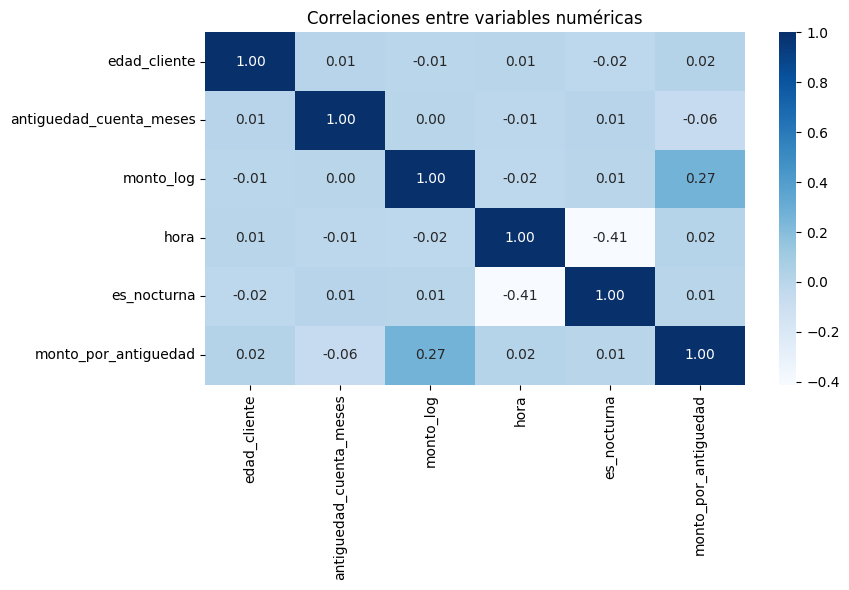

Correlaciones elevadas (|r| > 0.8):


In [96]:
# Matriz de correlación
correlaciones = X_train[numericas].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title('Correlaciones entre variables numéricas')
plt.tight_layout()
plt.show()

# Detectar correlaciones elevadas
print("Correlaciones elevadas (|r| > 0.8):")

for i in range(len(correlaciones.columns)):
    for j in range(i + 1, len(correlaciones.columns)):
        valor = correlaciones.iloc[i, j]
        if abs(valor) > 0.8:
            print(
                correlaciones.columns[i],
                "-",
                correlaciones.columns[j],
                ":",
                round(valor, 3)
            )

## Paso #11: K-Means

### Cuarta etapa: Minería de datos

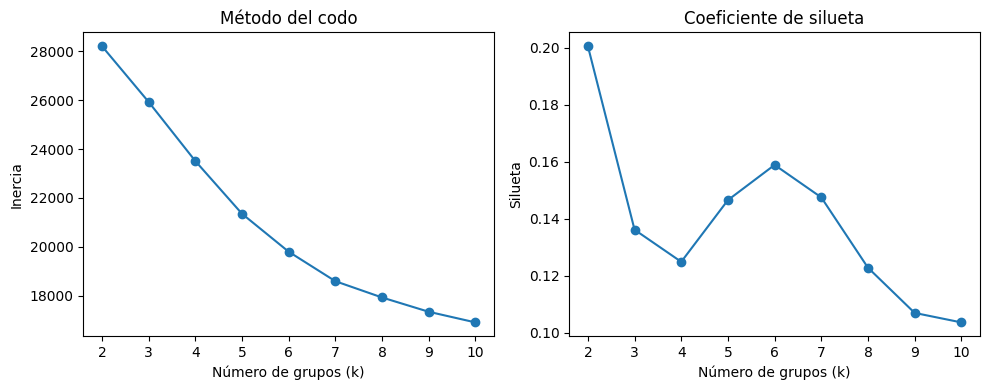

Mejor k según silueta: 2


In [97]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Preparar datos para agrupamiento
X_cluster = preprocesador.fit_transform(X_train)
X_cluster = np.asarray(
    X_cluster.toarray() if hasattr(X_cluster, "toarray")
    else X_cluster
)

inercias = []
siluetas = []
valores_k = range(2, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    etiquetas = modelo.fit_predict(X_cluster)
    inercias.append(modelo.inertia_)
    siluetas.append(
        silhouette_score(
            X_cluster, etiquetas,
            sample_size=1000,
            random_state=42
        )
    )

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(list(valores_k), inercias, marker='o')
plt.title('Método del codo')
plt.xlabel('Número de grupos (k)')
plt.ylabel('Inercia')

plt.subplot(1, 2, 2)
plt.plot(list(valores_k), siluetas, marker='o')
plt.title('Coeficiente de silueta')
plt.xlabel('Número de grupos (k)')
plt.ylabel('Silueta')

plt.tight_layout()
plt.show()

print("Mejor k según silueta:",
      list(valores_k)[np.argmax(siluetas)])

## Paso #12: DBSCAN

In [98]:
from sklearn.cluster import DBSCAN

# Aplicar DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=10)
etiquetas_dbscan = dbscan.fit_predict(X_cluster)

# Comparar anomalías con fraude
resultados_dbscan = pd.DataFrame({
    'grupo': etiquetas_dbscan,
    'es_fraude': y_train.to_numpy()
})

resultados_dbscan['anomalia'] = (
    resultados_dbscan['grupo'] == -1
)

print("Anomalías detectadas:",
      resultados_dbscan['anomalia'].sum())

print("\nTasa de fraude por grupo:")
print(
    resultados_dbscan.groupby('anomalia')['es_fraude'].mean() * 100
)

Anomalías detectadas: 62

Tasa de fraude por grupo:
anomalia
False     1.853733
True     22.580645
Name: es_fraude, dtype: float64


## Paso #13: Análisis de componentes principales (PCA)

Varianza explicada por componente:
[0.171 0.154 0.122]
Varianza acumulada (2 componentes): 0.324
Varianza acumulada (3 componentes): 0.446


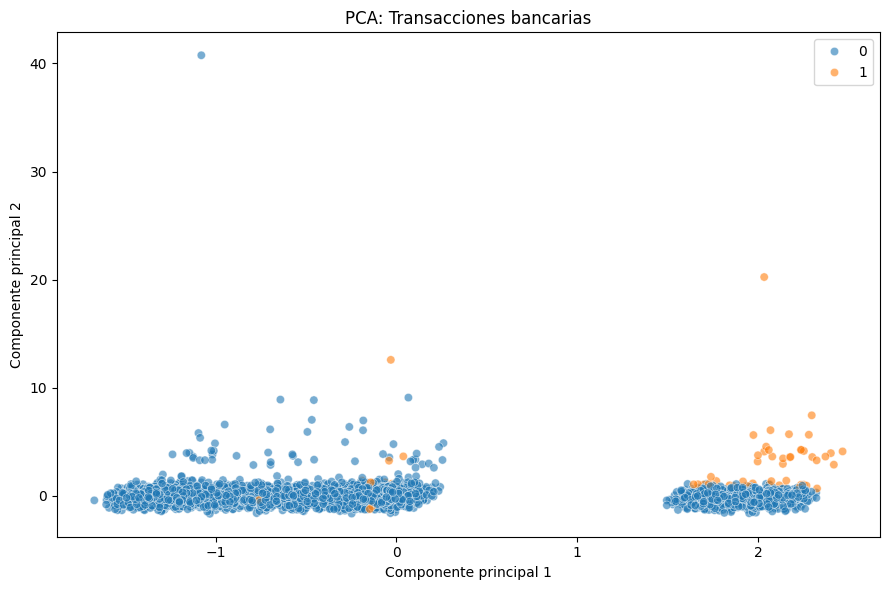

In [99]:
from sklearn.decomposition import PCA

# PCA con tres componentes
pca = PCA(n_components=3)
componentes = pca.fit_transform(X_cluster)

print("Varianza explicada por componente:")
print(pca.explained_variance_ratio_.round(3))

print("Varianza acumulada (2 componentes):",
      round(sum(pca.explained_variance_ratio_[:2]), 3))

print("Varianza acumulada (3 componentes):",
      round(sum(pca.explained_variance_ratio_), 3))

# Visualización PCA en dos dimensiones
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=componentes[:, 0],
    y=componentes[:, 1],
    hue=y_train.to_numpy(),
    alpha=0.6
)

plt.title('PCA: Transacciones bancarias')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.tight_layout()
plt.show()

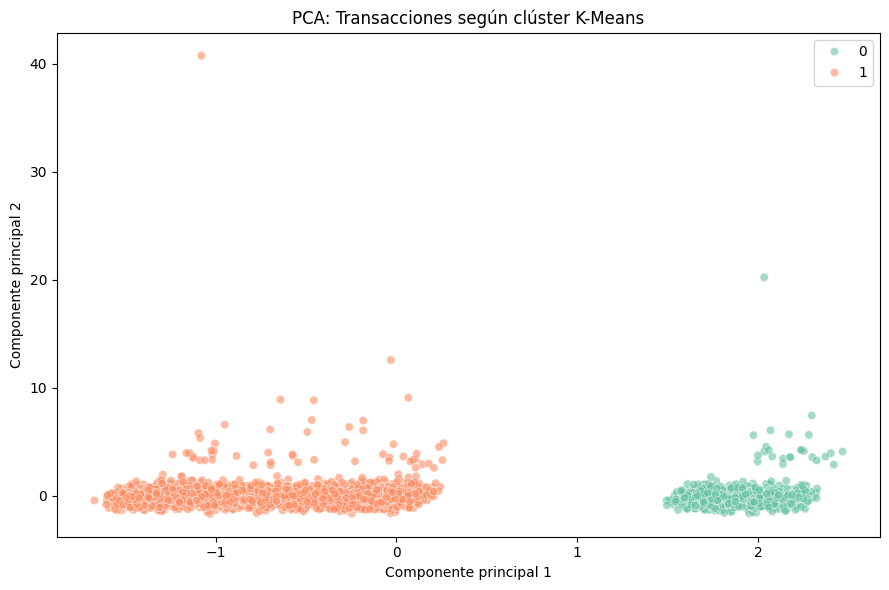

In [100]:
# PCA coloreado por clúster de K-Means

mejor_k = list(valores_k)[np.argmax(siluetas)]

kmeans_final = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=10
)

etiquetas_kmeans = kmeans_final.fit_predict(X_cluster)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=componentes[:, 0],
    y=componentes[:, 1],
    hue=etiquetas_kmeans,
    palette='Set2',
    alpha=0.6
)

plt.title('PCA: Transacciones según clúster K-Means')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.tight_layout()
plt.show()

## Paso #14: Modelos predictivos

In [101]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Regresión logística
modelo_logistico = Pipeline([
    ('preprocesador', preprocesador),
    ('modelo', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Random Forest
modelo_forest = Pipeline([
    ('preprocesador', preprocesador),
    ('modelo', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar modelos
modelo_logistico.fit(X_train, y_train)
modelo_forest.fit(X_train, y_train)

print("Modelos entrenados correctamente.")

Modelos entrenados correctamente.


## Paso #15: Evaluación de modelos predictivos

In [102]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

resultados = []

modelos = {
    'Regresión logística': modelo_logistico,
    'Random Forest': modelo_forest
}

for nombre, modelo in modelos.items():
    predicciones = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, predicciones),
        'Precision': precision_score(y_test, predicciones, zero_division=0),
        'Recall': recall_score(y_test, predicciones, zero_division=0),
        'F1': f1_score(y_test, predicciones, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilidades)
    })

df_resultados = pd.DataFrame(resultados)
print(df_resultados.round(3).to_string(index=False))

             Modelo  Accuracy  Precision  Recall    F1  ROC-AUC
Regresión logística     0.836      0.106   0.864 0.188    0.905
      Random Forest     0.995      1.000   0.773 0.872    0.893


## Paso #16: Matrices de confusión

### Quinta etapa: Interpretación y visualización

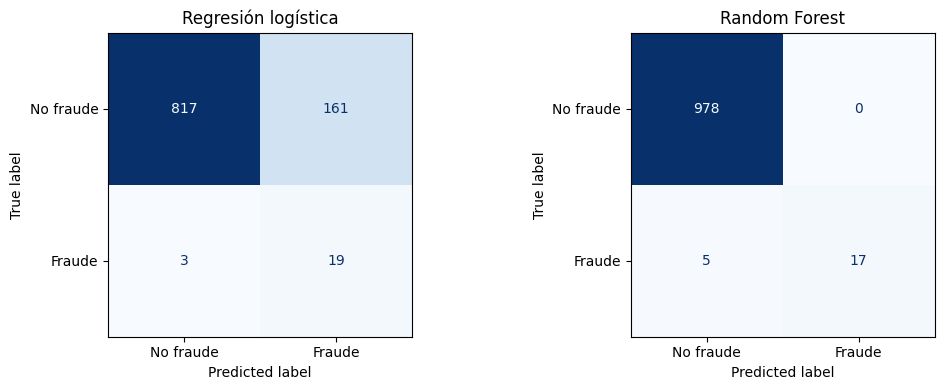

In [103]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):
    predicciones = modelo.predict(X_test)
    matriz = confusion_matrix(y_test, predicciones)

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=['No fraude', 'Fraude']
    ).plot(ax=ax, cmap='Blues', colorbar=False)

    ax.set_title(nombre)

plt.tight_layout()
plt.show()

## Paso #17: Curvas ROC

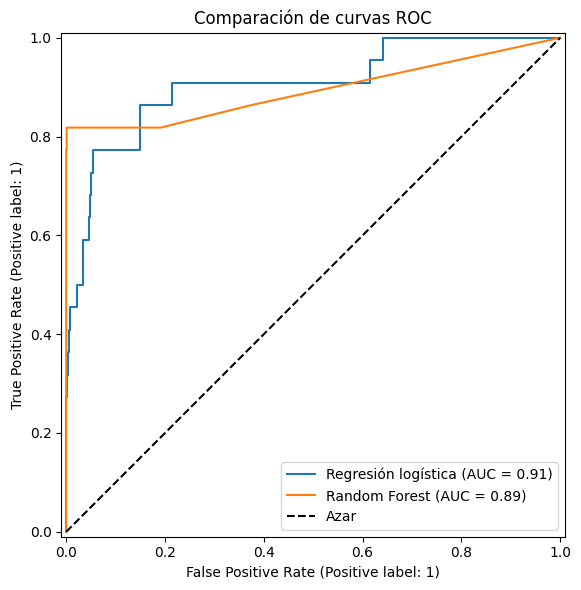

In [104]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))
ax = plt.gca()

for nombre, modelo in modelos.items():
    RocCurveDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        name=nombre,
        ax=ax
    )

plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.title('Comparación de curvas ROC')
plt.legend()
plt.tight_layout()
plt.show()

## Paso #18: Importancia de variables

num__monto_log                  0.319
num__monto_por_antiguedad       0.190
num__es_nocturna                0.096
num__hora                       0.095
num__antiguedad_cuenta_meses    0.089
num__edad_cliente               0.066
cat__tipo_transaccion_Retiro    0.013
cat__region_Cartago             0.012
cat__canal_App móvil            0.012
cat__canal_Web                  0.012
dtype: float64


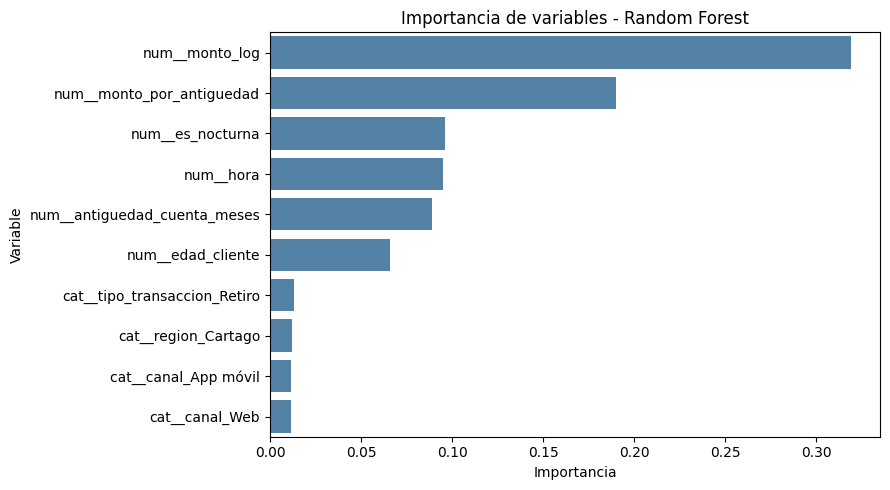

In [105]:
# Obtener importancia de variables

pre = modelo_forest.named_steps['preprocesador']
forest = modelo_forest.named_steps['modelo']

importancias = pd.Series(
    forest.feature_importances_,
    index=pre.get_feature_names_out()
).sort_values(ascending=False)

# Mostrar las 10 variables principales
print(importancias.head(10).round(3))

plt.figure(figsize=(9, 5))

sns.barplot(
    x=importancias.head(10).values,
    y=importancias.head(10).index,
    color='steelblue'
)

plt.title('Importancia de variables - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

## Paso #19: Dashboard de resultados

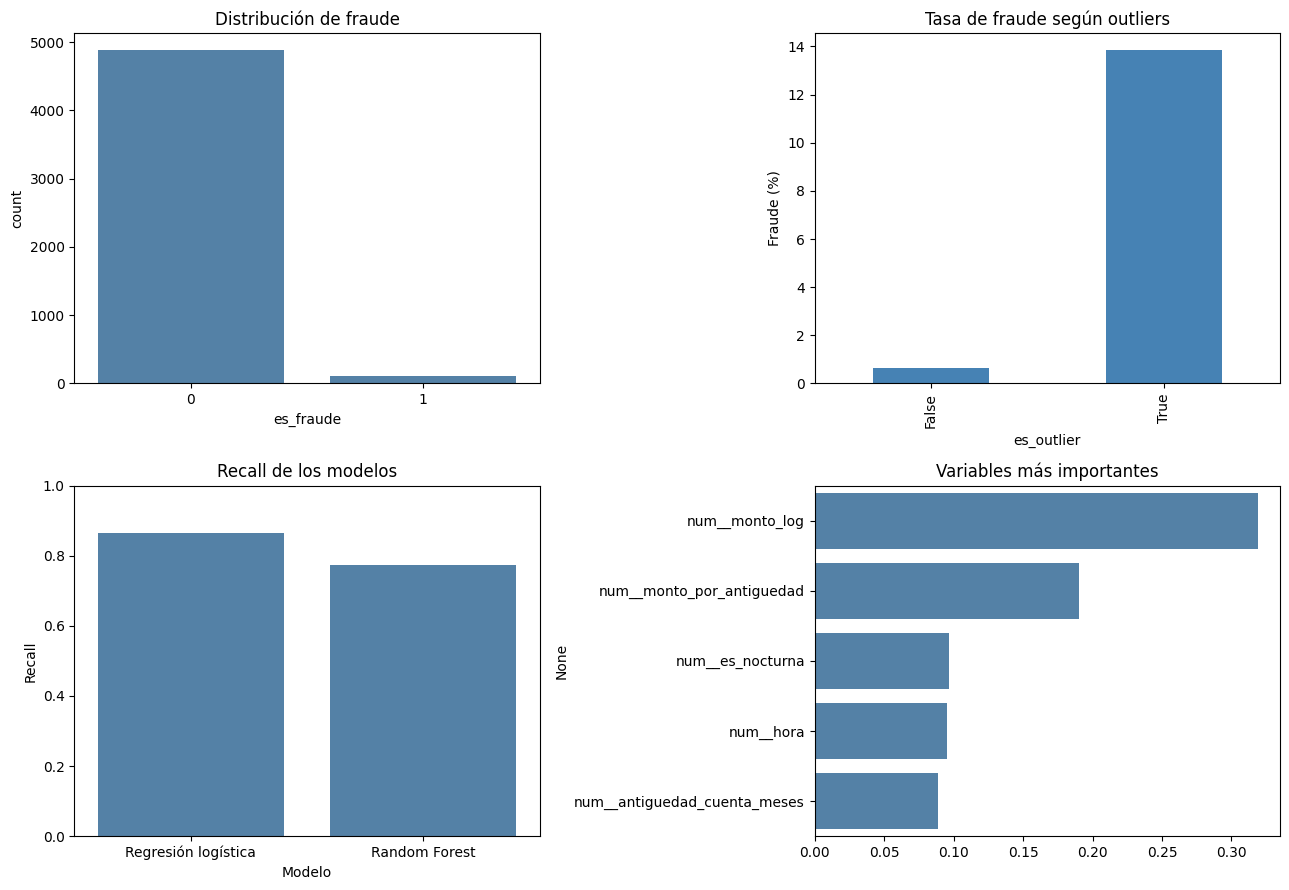

Dashboard guardado correctamente.


In [106]:
# Dashboard de cuatro gráficos

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Distribución de fraude
sns.countplot(
    data=df_limpio, x='es_fraude',
    ax=axes[0, 0], color='steelblue'
)
axes[0, 0].set_title('Distribución de fraude')

# 2. Fraude según valores atípicos
tasas = df_limpio.groupby('es_outlier')['es_fraude'].mean() * 100
tasas.plot(kind='bar', ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Tasa de fraude según outliers')
axes[0, 1].set_ylabel('Fraude (%)')

# 3. Comparación de modelos
sns.barplot(
    data=df_resultados,
    x='Modelo', y='Recall',
    ax=axes[1, 0], color='steelblue'
)
axes[1, 0].set_title('Recall de los modelos')
axes[1, 0].set_ylim(0, 1)

# 4. Importancia de variables
sns.barplot(
    x=importancias.head(5).values,
    y=importancias.head(5).index,
    ax=axes[1, 1], color='steelblue'
)
axes[1, 1].set_title('Variables más importantes')

plt.tight_layout()
plt.savefig('dashboard_kdd.png', dpi=150, bbox_inches='tight')
plt.show()

print("Dashboard guardado correctamente.")

## Paso #21: Resultados finales de los modelos

In [107]:
print("=== MODELOS PREDICTIVOS ===")
print(df_resultados.round(3).to_string(index=False))

print("\n=== K-MEANS ===")
print("Mejor k:", list(valores_k)[np.argmax(siluetas)])

print("\n=== DBSCAN ===")
print("Anomalías:", resultados_dbscan['anomalia'].sum())
print(resultados_dbscan.groupby('anomalia')['es_fraude'].mean() * 100)

print("\n=== PCA ===")
print("Varianza acumulada (2 componentes):",
      round(sum(pca.explained_variance_ratio_[:2]), 3))
print("Varianza acumulada (3 componentes):",
      round(sum(pca.explained_variance_ratio_), 3))

print("\n=== VARIABLES MÁS IMPORTANTES ===")
print(importancias.head(5).round(3))

=== MODELOS PREDICTIVOS ===
             Modelo  Accuracy  Precision  Recall    F1  ROC-AUC
Regresión logística     0.836      0.106   0.864 0.188    0.905
      Random Forest     0.995      1.000   0.773 0.872    0.893

=== K-MEANS ===
Mejor k: 2

=== DBSCAN ===
Anomalías: 62
anomalia
False     1.853733
True     22.580645
Name: es_fraude, dtype: float64

=== PCA ===
Varianza acumulada (2 componentes): 0.324
Varianza acumulada (3 componentes): 0.446

=== VARIABLES MÁS IMPORTANTES ===
num__monto_log                  0.319
num__monto_por_antiguedad       0.190
num__es_nocturna                0.096
num__hora                       0.095
num__antiguedad_cuenta_meses    0.089
dtype: float64


## Paso #23: Dependencias del proyecto

In [108]:
# Crear archivo de dependencias

import importlib.metadata as metadata

bibliotecas = [
    'numpy',
    'pandas',
    'matplotlib',
    'seaborn',
    'scikit-learn'
]

with open('requirements.txt', 'w') as archivo:
    for biblioteca in bibliotecas:
        version = metadata.version(biblioteca)
        archivo.write(f'{biblioteca}=={version}\n')

print("requirements.txt creado correctamente.")

with open('requirements.txt') as archivo:
    print(archivo.read())

requirements.txt creado correctamente.
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1




#Conclusiones finales

## Resultados del proyecto

Durante el desarrollo del proyecto se aplicaron las cinco etapas del modelo KDD para analizar transacciones bancarias y así poder identificar posibles fraudes.

En la etapa de preprocesamiento se trabajaron los valores faltantes y se identificaron transacciones con montos fuera de lo habitual. Se observó que estas transacciones presentaban una mayor proporción de fraude, por lo que se decidió conservarlas para el análisis.

Posteriormente, se realizaron transformaciones y se crearon nuevas variables para facilitar el trabajo con los datos.

En la etapa de minería se utilizaron K-Means y DBSCAN para identificar grupos y posibles anomalías. También se aplicó PCA para reducir la cantidad de variables y visualizar mejor las relaciones entre las transacciones.

Finalmente, se entrenaron dos modelos predictivos: regresión logística y Random Forest. Ambos presentaron resultados diferentes. La regresión logística logró identificar una mayor cantidad de fraudes, mientras que Random Forest obtuvo mejores resultados en precisión y F1-score.

## Recomendación final

A partir de los resultados, Random Forest podría ser una buena opción para identificar transacciones sospechosas con menos falsas alarmas. Sin embargo, la regresión logística también resulta útil porque logra detectar una mayor proporción de fraudes.

Además, se observó que el monto y el horario de las transacciones son variables importantes para el análisis.

En general, el proyecto permitió comprender cómo las diferentes etapas del modelo KDD ayudan a transformar datos bancarios en información útil para apoyar la detección de fraude.

Antes de utilizar estos modelos en un entorno real, sería necesario realizar más pruebas y evaluar sus resultados con nuevos datos.